# AKS Moments Workflow (astro-carla)

This notebook runs an end-to-end adaptive-kernel-smoothing (AKS) and moments
workflow for a 3D spectroscopic datacube.

It supports:
- optional AKS generation from an input science cube (+ optional variance cube),
- per-structure moment-map generation,
- spectra comparison between RAW and AKS cubes,
- and final 2x2 moment-panel plotting.

The notebook is configured through `dataset_configs` and can be adapted to any
cube by changing file paths and AKS parameters.


## 0) Paths and run toggle
Set input/output paths and choose a dataset entry from `dataset_configs`.

Set `RUN_AKS = True` to regenerate AKS products from the input cube(s).
If AKS outputs already exist and you only want moments/plots, leave `RUN_AKS = False`.


In [1]:
from pathlib import Path
import json
import hashlib
from datetime import datetime
import numpy as np

# Root of this repo
repo_root = Path('.')

# Input cube folder (already organized)
inputs_folder = repo_root / 'KCWI' / 'inputs'

# Dataset configs
dataset_configs = {
    'RGguy_icubed_Lya': {
        'scube': 'RGguy_icubed_Lya.fits',
        'varcube': 'RGguy_icubed_Lya.var.fits',
        'aks_params': {
            'r0': 1, 'r1': 7, 'rstep': 1, 'roperation': 'sum',
            'w0': 1, 'w1': 1.5, 'wstep': 1, 'woperation': 'sum',
            'min_group_size': 500, 'snr_threshold': 3,
            'zmin': 0, 'zmax': 110,
            'extraname': ''
        },
        'physics': {
            'redshift': 1.986,
            'redshift_err': 0.014,
            'line_rest_aa': 1215.67,
            'kcwi2cgs': 1e-17,
            'disp2fwhm': 2.3548
        }
    }
}

# Select dataset here
dataset = 'RGguy_icubed_Lya'
cfg = dataset_configs[dataset]
aks_params = cfg['aks_params']
physics_params = cfg.get('physics', {})

# Centralized physical/calibration parameters (dataset-driven)
redshift = float(physics_params.get('redshift', 1.986))
redshift_err = float(physics_params.get('redshift_err', 0.014))
line_rest_aa = float(physics_params.get('line_rest_aa', 1215.67))
kcwi2cgs = float(physics_params.get('kcwi2cgs', 1e-17))
disp2fwhm = float(physics_params.get('disp2fwhm', 2.3548))


run_id = (
    f"r{aks_params['r0']}-{aks_params['r1']}_{aks_params['roperation']}"
    f"__w{aks_params['w0']}-{aks_params['w1']}_{aks_params['woperation']}"
    f"__snr{aks_params['snr_threshold']}__z{aks_params['zmin']}-{aks_params['zmax']}"
    f"__min{aks_params['min_group_size']}"
)

# Output roots
runs_root = repo_root / 'KCWI' / 'runs' / dataset
aks_folder = runs_root / 'aks' / run_id
moments_folder = runs_root / 'moments' / run_id
plots_folder = runs_root / 'plots' / run_id

# Toggle AKS computation
RUN_AKS = False

# Performance/quality toggles
AKS_WORK_DTYPE = np.float32
MOMENT_REFINE_GAUSSIAN = True
MOMENT_FIT_SNR_THRESHOLD = 8.0


## 1) Imports
Core libraries for numerical operations, FITS I/O, smoothing, fitting, and plotting.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from astropy.io import fits
from astropy.io.fits import PrimaryHDU
from astropy.utils.data import get_pkg_data_filename
from scipy.ndimage import convolve1d, label
from tqdm import tqdm
from scipy.optimize import curve_fit


## 2) AKS helper functions
Utility functions for:
- configurable parameter ranges,
- Gaussian kernels and separable smoothing,
- optional variance estimation,
- connected-component filtering,
- and the main adaptive kernel smoothing routine.


In [3]:
def custom_range(start, stop, step, operation='sum'):
    def do_step(x, step_):
        if (operation == 'sum') or (operation == 'reduce'):
            return x + step_
        if operation == 'multiply':
            return x * step_
        if operation == 'exponent':
            return x ** step_
        raise ValueError(f'Unsupported operation: {operation}')

    x = start
    if start == stop:
        yield x
        return
    while (start < stop and x <= stop) or (start > stop and x >= stop):
        yield x
        x = do_step(x, step)


def gaussian_kernel1d(sigma, truncate=3.5, dtype=np.float32):
    sigma = float(sigma)
    if sigma <= 0:
        return np.array([1.0], dtype=dtype)
    radius = int(truncate * sigma + 0.5)
    x = np.arange(-radius, radius + 1, dtype=np.float64)
    k = np.exp(-0.5 * (x / sigma) ** 2)
    k /= np.sum(k)
    return k.astype(dtype)


def reduce_wavelength_dimension(datacube, layer_width, average=False):
    num_layers_to_remove = datacube.shape[0] % layer_width
    if num_layers_to_remove != 0:
        datacube = datacube[:-num_layers_to_remove]
    new_shape = (-1, layer_width) + datacube.shape[1:]
    reduced = np.nansum(datacube.reshape(new_shape), axis=1)
    if average:
        reduced = reduced / float(layer_width)
    return reduced


def estimate_variance_from_cube(datacube):
    std = np.nanstd(datacube, axis=(1, 2))
    mask = np.abs(datacube) > (3 * std[:, None, None])
    masked = np.ma.masked_array(datacube, mask=mask)
    var_1d = np.ma.var(masked, axis=(1, 2)).filled(np.nan)
    variance_cube = np.zeros_like(datacube) + var_1d[:, None, None]
    return variance_cube


def group_select(mask, min_size=10):
    labeled, num_features = label(mask)
    if num_features == 0:
        return np.zeros(mask.shape, dtype=np.int32)

    sizes = np.bincount(labeled.ravel())
    keep_ids = np.where(sizes >= min_size)[0]
    keep_ids = keep_ids[keep_ids != 0]

    out = np.zeros(mask.shape, dtype=np.int32)
    for new_id, old_id in enumerate(keep_ids, start=1):
        out[labeled == old_id] = new_id
    return out


def _smooth2d_separable(arr2d, k1d):
    return convolve1d(convolve1d(arr2d, k1d, axis=0, mode='constant', cval=0.0),
                      k1d, axis=1, mode='constant', cval=0.0)


def adaptive_kernel_smooth(
    datacube,
    snr_threshold,
    variance=None,
    r0=1,
    r1=10,
    rstep=1.0,
    roperation='sum',
    w0=8,
    w1=1,
    wstep=0.5,
    woperation='multiply',
    min_group_size=1,
    eps=1e-12,
    work_dtype=np.float32,
    truncate=3.5,
):
    datacube = np.asarray(datacube, dtype=work_dtype)
    num_wavelengths, height, width = datacube.shape
    ntot = height * width

    if variance is None:
        variance = estimate_variance_from_cube(datacube)
    else:
        variance = np.asarray(variance, dtype=work_dtype)
        if variance.shape != datacube.shape:
            raise ValueError('variance must have same shape as datacube')

    smoothed_datacube = np.zeros_like(datacube, dtype=work_dtype)
    smoothed_variancecube = np.zeros_like(datacube, dtype=work_dtype)
    cubemask = np.zeros(datacube.shape, dtype=bool)
    detected_voxels_stats = []

    wrange = list(custom_range(w0, w1, wstep, operation=woperation))
    rrange = list(custom_range(r0, r1, rstep, operation=roperation))
    print('wavelength operation:', woperation)
    print('radial range', rrange)
    print('wavelength range', wrange)

    spatial_kernels = {s: gaussian_kernel1d(s, truncate=truncate, dtype=work_dtype) for s in rrange}
    spatial_kernels_sq = {s: (k ** 2).astype(work_dtype) for s, k in spatial_kernels.items()}

    for ww in tqdm(wrange, desc='Wavelength smoothing Loop', position=0):
        if woperation == 'reduce':
            w_int = int(ww)
            working_cube = reduce_wavelength_dimension(datacube, w_int, average=False)
            working_cubevariance = reduce_wavelength_dimension(variance, w_int, average=False)
            _num_wavelengths = working_cube.shape[0]
            print(f'reducing wavelength to {_num_wavelengths} layers, originally {num_wavelengths}')
        else:
            _num_wavelengths = num_wavelengths
            if ww > 0:
                kw = gaussian_kernel1d(ww, truncate=truncate, dtype=work_dtype)
                kw_sq = (kw ** 2).astype(work_dtype)
                working_cube = convolve1d(datacube, kw, axis=0, mode='constant', cval=0.0)
                working_cubevariance = convolve1d(variance, kw_sq, axis=0, mode='constant', cval=0.0)
            else:
                working_cube = datacube
                working_cubevariance = variance

        for w_idx in tqdm(range(_num_wavelengths), desc='Wavelength layers Loop', position=0):
            data_layer = working_cube[w_idx]
            variance_layer = working_cubevariance[w_idx]

            if woperation == 'reduce':
                base = int(w_idx * ww)
                idx_list = [base + k for k in range(int(ww)) if (base + k) < num_wavelengths]
                mask = np.any(cubemask[idx_list], axis=0) if idx_list else np.zeros((height, width), dtype=bool)
            else:
                idx_list = [w_idx]
                idx = min(w_idx, cubemask.shape[0] - 1)
                mask = cubemask[idx]

            nvox = 0
            detected_voxels_wav = []

            for scale in rrange:
                kxy = spatial_kernels[scale]
                kxy_sq = spatial_kernels_sq[scale]

                smoothed_data = _smooth2d_separable(data_layer, kxy)
                smoothed_variance = _smooth2d_separable(variance_layer, kxy_sq)
                snr = smoothed_data / np.sqrt(smoothed_variance + eps)

                detected_voxels = (snr / scale > snr_threshold) & (~mask)
                n_new = int(np.count_nonzero(detected_voxels))
                nvox += n_new
                detected_voxels_wav.append(nvox)

                if n_new > 0:
                    for idx in idx_list:
                        if idx >= cubemask.shape[0]:
                            continue
                        cubemask[idx] |= detected_voxels
                        smoothed_datacube[idx][detected_voxels] += smoothed_data[detected_voxels]
                        smoothed_variancecube[idx][detected_voxels] += smoothed_variance[detected_voxels]
                    mask |= detected_voxels

                if nvox >= ntot:
                    break

            detected_voxels_stats.append(detected_voxels_wav)

    mask_original = (datacube == 0) | ~np.isfinite(datacube) | ~np.isfinite(variance)
    cubemask[mask_original] = False
    smoothed_datacube[mask_original] = 0
    smoothed_variancecube[mask_original] = 0

    label_mask = group_select(cubemask, min_size=min_group_size) if min_group_size > 1 else group_select(cubemask, min_size=1)
    keep = label_mask > 0
    smoothed_datacube[~keep] = 0
    smoothed_variancecube[~keep] = 0

    good_data = keep & np.isfinite(datacube) & np.isfinite(variance)
    for i in range(label_mask.shape[0]):
        layer_mask = good_data[i]
        if not np.any(layer_mask):
            continue
        orig_sum = np.nansum(datacube[i][layer_mask])
        orig_var_sum = np.nansum(variance[i][layer_mask])
        aks_sum = np.nansum(smoothed_datacube[i][layer_mask])
        aks_var_sum = np.nansum(smoothed_variancecube[i][layer_mask])

        if np.isfinite(orig_sum) and np.isfinite(aks_sum) and aks_sum != 0:
            smoothed_datacube[i] *= orig_sum / aks_sum
        if np.isfinite(orig_var_sum) and np.isfinite(aks_var_sum) and aks_var_sum != 0:
            smoothed_variancecube[i] *= orig_var_sum / aks_var_sum

    return smoothed_datacube, smoothed_variancecube, label_mask.astype(np.int32), detected_voxels_stats, variance


## 3) Load the input datacube from KCWI
Loads the selected science cube and (optionally) variance cube from the configured
input directory.

The specific files are selected by the active `dataset` entry in `dataset_configs`.


In [4]:
cube_name = dataset

# Input file names from dataset config
scube = inputs_folder / cfg['scube']
varcube = inputs_folder / cfg['varcube']

cube = fits.getdata(get_pkg_data_filename(str(scube)), ext=0).copy()

try:
    variance = fits.getdata(get_pkg_data_filename(str(varcube)), ext=0).copy()
except Exception:
    variance = None

header = fits.getheader(str(scube))
cube.shape

# Resolve spectral/spatial scales once from header (allow optional per-dataset override).
pix2angstrom = float(physics_params.get('pix2angstrom', abs(float(header.get('CDELT3', header.get('CD3_3', 1.0))))))
pix2asec = float(physics_params.get('pix2asec', abs(float(header.get('CDELT2', header.get('CD2_2', 0.3 / 3600.0)))) * 3600.0))

print('Variance cube:', 'loaded' if variance is not None else 'missing (will estimate)')
print(
    f"Physics: z={redshift:.3f}+-{redshift_err:.3f}, line_rest={line_rest_aa:.2f} AA, "
    f"kcwi2cgs={kcwi2cgs:.2e}, disp2fwhm={disp2fwhm:.4f}, "
    f"pix2angstrom={pix2angstrom:.6f}, pix2asec={pix2asec:.6f}"
)


Variance cube: loaded
Physics: z=1.986+-0.014, line_rest=1215.67 AA, kcwi2cgs=1.00e-17, disp2fwhm=2.3548, pix2angstrom=1.000000, pix2asec=0.291456


## 4) Run AKS (optional)
Runs AKS on the configured spectral window and writes run products
(mask, AKS cube, AKS variance/SNR, and structure subcubes) into the run folder.


In [5]:
if RUN_AKS:
    params = aks_params

    zmin, zmax = params['zmin'], params['zmax']
    datacube_cropped = cube[zmin:zmax + 1].copy().astype(AKS_WORK_DTYPE)
    variance_cropped = None if variance is None else variance[zmin:zmax + 1].copy().astype(AKS_WORK_DTYPE)

    # Apply central crater mask (from old cube: y=23–34, x=45–61)
    datacube_cropped[:, 23:35, 45:62] = 0
    if variance_cropped is not None:
        variance_cropped[:, 23:35, 45:62] = 0

    # Save cropped inputs for debugging
    debug_dir = aks_folder / 'debug'
    debug_dir.mkdir(parents=True, exist_ok=True)
    hdu_dbg = PrimaryHDU()
    hdu_dbg.header = header.copy()
    hdu_dbg.data = datacube_cropped
    hdu_dbg.writeto(debug_dir / 'cropped_input.fits', overwrite=True)
    if variance_cropped is not None:
        hdu_dbg.data = variance_cropped
        hdu_dbg.writeto(debug_dir / 'cropped_variance.fits', overwrite=True)

    smoothed_cube, smoothed_variancecube, cubemask, detected_stats, original_variance = adaptive_kernel_smooth(
        datacube_cropped, params['snr_threshold'], variance_cropped,
        params['r0'], params['r1'], params['rstep'], params['roperation'],
        params['w0'], params['w1'], params['wstep'], params['woperation'], params['min_group_size'],
        work_dtype=AKS_WORK_DTYPE
    )

    aks_folder.mkdir(parents=True, exist_ok=True)
    hdu = PrimaryHDU()
    hdu.header = header.copy()

    # Save labeled mask (int IDs)
    hdu.data = cubemask.astype(np.int32)
    hdu.writeto(aks_folder / 'AKS.mask.fits', overwrite=True)

    # Save smoothed cube and IM
    hdu.data = smoothed_cube.astype(np.float32)
    hdu.writeto(aks_folder / 'AKS.fits', overwrite=True)
    hdu.data = np.nansum(smoothed_cube, axis=0).astype(np.float32)
    hdu.writeto(aks_folder / 'AKS.IM.fits', overwrite=True)

    # Save variance and SNR
    smoothed_var = smoothed_variancecube.copy().astype(np.float32)
    hdu.data = smoothed_var
    hdu.writeto(aks_folder / 'AKS.var.fits', overwrite=True)
    snr_cube = smoothed_cube / np.sqrt(smoothed_var + 1e-12)
    snr_cube[~np.isfinite(snr_cube)] = 0
    hdu.data = snr_cube.astype(np.float32)
    hdu.writeto(aks_folder / 'AKS.snr.fits', overwrite=True)

    # Save original cropped cube
    hdu.data = datacube_cropped.astype(np.float32)
    hdu.writeto(aks_folder / 'orig.fits', overwrite=True)

    # Create subcubes from label IDs
    subcube_dir = aks_folder / 'subcubes'
    subcube_dir.mkdir(parents=True, exist_ok=True)

    structure_ids = np.unique(cubemask[cubemask > 0])

    for sid in structure_ids:
        structure_mask = (cubemask == sid)
        indices = np.where(structure_mask)
        zmin_sub, zmax_sub = np.min(indices[0]), np.max(indices[0])
        ymin_sub, ymax_sub = np.min(indices[1]), np.max(indices[1])
        xmin_sub, xmax_sub = np.min(indices[2]), np.max(indices[2])

        subcube = smoothed_cube[zmin_sub:zmax_sub+1, ymin_sub:ymax_sub+1, xmin_sub:xmax_sub+1].copy()
        hdu.data = subcube.astype(np.float32)
        hdu.writeto(subcube_dir / f'AKS.{int(sid)}.fits', overwrite=True)

        sub_im = np.nansum(subcube, axis=0)
        hdu.data = sub_im.astype(np.float32)
        hdu.writeto(subcube_dir / f'AKS.{int(sid)}.IM.fits', overwrite=True)

    # Write metadata
    def file_md5(p):
        h = hashlib.md5()
        with open(p, 'rb') as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b''):
                h.update(chunk)
        return h.hexdigest()

    metadata = {
        'dataset': dataset,
        'run_id': run_id,
        'params': params,
        'inputs': {
            'cube': str(scube),
            'cube_md5': file_md5(scube),
            'var': str(varcube),
            'var_md5': file_md5(varcube) if varcube.exists() else None
        },
        'performance': {
            'work_dtype': str(np.dtype(AKS_WORK_DTYPE)),
            'spatial_smoothing': 'separable gaussian (convolve1d)',
            'spectral_smoothing': 'convolve1d axis=0'
        },
        'timestamp_utc': datetime.utcnow().isoformat() + 'Z'
    }
    with open(aks_folder / 'metadata.json', 'w') as f:
        json.dump(metadata, f, indent=2)

    print('AKS folder created:', aks_folder)
else:
    if not aks_folder.exists():
        raise FileNotFoundError(
            f'AKS folder does not exist: {aks_folder}\n'
            'Set RUN_AKS = True to generate it.'
        )
    print('Using existing AKS folder:', aks_folder)


Using existing AKS folder: KCWI/runs/RGguy_icubed_Lya/aks/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500


## 4.5) Generate AKS moment maps
Computes per-structure moment products for both AKS and RAW cubes:
- integrated flux (`IM`),
- centroid velocity (`cen`),
- linewidth (`fwhm`),
- and voxel counts (`nvox`).


In [6]:
def gaussian(x, amp, mu, sigma):
    return np.abs(amp) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)


def gaussian_fit(x, y, p0=None):
    try:
        mask = np.isfinite(y)
        x, y = x[mask], y[mask]
        if len(x) < 5:
            return np.nan, np.nan, np.nan
        if p0 is None:
            p0 = [np.nanmax(y), x[np.nanargmax(y)], 1.0]
        bounds = ([0.0, x.min(), 1e-3], [np.inf, x.max(), x.max() - x.min() + 1.0])
        popt, _ = curve_fit(gaussian, x, y, p0=p0, bounds=bounds, maxfev=4000)
        amp, cen, sigma = popt
        return amp, cen, sigma
    except Exception:
        return np.nan, np.nan, np.nan


def pix2vel(x, pix2angstrom=pix2angstrom, z=redshift, line=line_rest_aa):
    return x * pix2angstrom * 3e5 / line / (1. + z)


def compute_moment_maps(subcube, mask_sub, variance_sub=None, refine_gaussian=True, fit_snr_threshold=8.0):
    z = np.arange(subcube.shape[0], dtype=np.float32)[:, None, None]

    valid = mask_sub & np.isfinite(subcube)
    flux = np.where(valid, subcube, 0.0).astype(np.float32)

    m0 = np.sum(flux, axis=0)
    m0_safe = np.where(m0 > 0, m0, np.nan)

    m1 = np.sum(flux * z, axis=0) / m0_safe
    var2 = np.sum(flux * (z - m1[None, :, :]) ** 2, axis=0) / m0_safe
    sigma = np.sqrt(np.clip(var2, 0.0, np.inf))
    fwhm_pix = disp2fwhm * sigma

    nvox = np.sum(valid & (flux > 0), axis=0).astype(np.float32)

    total_flux = np.nansum(m0)
    flux_weighted_centroid = np.nansum(m0 * m1) / total_flux if total_flux > 0 else np.nan
    cen_pix = m1 - flux_weighted_centroid

    if variance_sub is not None:
        vflux = np.where(mask_sub & np.isfinite(variance_sub), variance_sub, 0.0).astype(np.float32)
        sigma_m0 = np.sqrt(np.sum(vflux, axis=0))
        snr_map = m0 / (sigma_m0 + 1e-12)
    else:
        peak = np.nanmax(np.where(valid, subcube, np.nan), axis=0)
        noise = np.nanstd(np.where(valid, subcube, np.nan), axis=0)
        snr_map = peak / (noise + 1e-12)

    if refine_gaussian:
        xdata = np.arange(subcube.shape[0], dtype=np.float32)
        candidates = np.where((snr_map >= fit_snr_threshold) & np.isfinite(cen_pix) & np.isfinite(fwhm_pix))
        for y, x in zip(*candidates):
            yspec = subcube[:, y, x]
            p0 = [float(np.nanmax(yspec)), float(m1[y, x]), float(max(sigma[y, x], 0.8))]
            _, cen_fit, sig_fit = gaussian_fit(xdata, yspec, p0=p0)
            if np.isfinite(cen_fit):
                cen_pix[y, x] = cen_fit - flux_weighted_centroid
            if np.isfinite(sig_fit):
                fwhm_pix[y, x] = disp2fwhm * sig_fit

    im_log = np.full_like(m0, np.nan, dtype=np.float32)
    sb = m0 * kcwi2cgs
    pos = sb > 0
    im_log[pos] = np.log10(sb[pos])

    cen_vel = pix2vel(cen_pix)
    fwhm_vel = pix2vel(fwhm_pix)

    invalid = ~np.any(valid, axis=0)
    im_log[invalid] = np.nan
    cen_vel[invalid] = np.nan
    fwhm_vel[invalid] = np.nan
    nvox[invalid] = np.nan

    return im_log.astype(np.float32), cen_vel.astype(np.float32), fwhm_vel.astype(np.float32), nvox.astype(np.float32)


subcube_dir = aks_folder / 'subcubes'
moments_subcube_dir = moments_folder / 'subcubes'
moments_subcube_dir.mkdir(parents=True, exist_ok=True)

# Ensure AKS outputs exist
mask_path = aks_folder / 'AKS.mask.fits'
if not mask_path.exists():
    raise FileNotFoundError('AKS outputs not found. Run AKS first to generate AKS.mask.fits')

maskcube = fits.getdata(mask_path)
aks_cube = fits.getdata(aks_folder / 'AKS.fits')
aks_var_path = aks_folder / 'AKS.var.fits'
aks_var = fits.getdata(aks_var_path) if aks_var_path.exists() else None

# Match spectral depth between full cube and AKS mask
zmin, zmax = aks_params['zmin'], aks_params['zmax']
raw_cube_match = cube[zmin:zmax + 1]
raw_var_match = None
if variance is not None:
    raw_var_match = variance[zmin:zmax + 1]

# Only 3D AKS subcubes (exclude 2D IM products)
subcube_files = sorted([p for p in subcube_dir.glob('AKS.*.fits') if p.name.count('.') == 2])

for subcube_file in subcube_files:
    parts = subcube_file.name.split('.')
    if len(parts) < 2:
        continue
    sub_id = int(parts[1])

    structure_mask = (maskcube == sub_id)
    z_idx, y_idx, x_idx = np.where(structure_mask)
    if len(z_idx) == 0:
        continue
    zmin_sub, zmax_sub = z_idx.min(), z_idx.max()
    ymin_sub, ymax_sub = y_idx.min(), y_idx.max()
    xmin_sub, xmax_sub = x_idx.min(), x_idx.max()
    mask_sub = structure_mask[zmin_sub:zmax_sub+1, ymin_sub:ymax_sub+1, xmin_sub:xmax_sub+1]

    # Output paths
    out_im_aks = moments_subcube_dir / f'AKS.{sub_id}.IM.fits'
    out_cen_aks = moments_subcube_dir / f'AKS.{sub_id}.cen.fits'
    out_fwhm_aks = moments_subcube_dir / f'AKS.{sub_id}.fwhm.fits'
    out_nvox_aks = moments_subcube_dir / f'AKS.{sub_id}.nvox.fits'

    out_im_raw = moments_subcube_dir / f'RAW.{sub_id}.IM.fits'
    out_cen_raw = moments_subcube_dir / f'RAW.{sub_id}.cen.fits'
    out_fwhm_raw = moments_subcube_dir / f'RAW.{sub_id}.fwhm.fits'
    out_nvox_raw = moments_subcube_dir / f'RAW.{sub_id}.nvox.fits'

    # --- AKS moments ---
    subcube_aks = aks_cube[zmin_sub:zmax_sub+1, ymin_sub:ymax_sub+1, xmin_sub:xmax_sub+1].copy()
    subcube_aks[~mask_sub] = np.nan

    var_sub_aks = None
    if aks_var is not None:
        var_sub_aks = aks_var[zmin_sub:zmax_sub+1, ymin_sub:ymax_sub+1, xmin_sub:xmax_sub+1].copy()
        var_sub_aks[~mask_sub] = np.nan

    im_AKS, cen_AKS, fwhm_AKS, nvox_AKS = compute_moment_maps(
        subcube_aks,
        mask_sub,
        variance_sub=var_sub_aks,
        refine_gaussian=MOMENT_REFINE_GAUSSIAN,
        fit_snr_threshold=MOMENT_FIT_SNR_THRESHOLD,
    )

    hdu = PrimaryHDU()
    hdu.data = im_AKS
    hdu.writeto(out_im_aks, overwrite=True)
    hdu.data = fwhm_AKS
    hdu.writeto(out_fwhm_aks, overwrite=True)
    hdu.data = cen_AKS
    hdu.writeto(out_cen_aks, overwrite=True)
    hdu.data = nvox_AKS
    hdu.writeto(out_nvox_aks, overwrite=True)

    # --- RAW moments (original cube masked by structure ID) ---
    raw_sub = raw_cube_match[zmin_sub:zmax_sub+1, ymin_sub:ymax_sub+1, xmin_sub:xmax_sub+1].copy()
    raw_sub[~mask_sub] = np.nan

    var_sub_raw = None
    if raw_var_match is not None:
        var_sub_raw = raw_var_match[zmin_sub:zmax_sub+1, ymin_sub:ymax_sub+1, xmin_sub:xmax_sub+1].copy()
        var_sub_raw[~mask_sub] = np.nan

    im_raw, cen_raw, fwhm_raw, nvox_raw = compute_moment_maps(
        raw_sub,
        mask_sub,
        variance_sub=var_sub_raw,
        refine_gaussian=MOMENT_REFINE_GAUSSIAN,
        fit_snr_threshold=MOMENT_FIT_SNR_THRESHOLD,
    )

    hdu.data = im_raw
    hdu.writeto(out_im_raw, overwrite=True)
    hdu.data = fwhm_raw
    hdu.writeto(out_fwhm_raw, overwrite=True)
    hdu.data = cen_raw
    hdu.writeto(out_cen_raw, overwrite=True)
    hdu.data = nvox_raw
    hdu.writeto(out_nvox_raw, overwrite=True)

# Write metadata for moments stage
moments_folder.mkdir(parents=True, exist_ok=True)
moments_meta = {
    'dataset': dataset,
    'run_id': run_id,
    'params': aks_params,
    'aks_folder': str(aks_folder),
    'moment_method': {
        'core': 'vectorized flux moments (M0/M1/M2)',
        'gaussian_refinement': bool(MOMENT_REFINE_GAUSSIAN),
        'fit_snr_threshold': float(MOMENT_FIT_SNR_THRESHOLD),
        'pix2angstrom': float(pix2angstrom),
        'pix2asec': float(pix2asec),
    },
    'timestamp_utc': datetime.utcnow().isoformat() + 'Z'
}
with open(moments_folder / 'metadata.json', 'w') as f:
    json.dump(moments_meta, f, indent=2)

print('Moment maps generated (AKS and RAW).')


Moment maps generated (AKS and RAW).


## 4.6) Spectra comparison (RAW vs AKS)
Plots integrated spectra for detected structures to compare RAW and AKS behavior
on the same masks.


Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/raw_spectra_by_structure.pdf | z_sys=1.986+-0.014 | lambda_sys=3629.99+-17.02 Angstrom | z-range=33:88 | lambda=[3602.00, 3657.00]


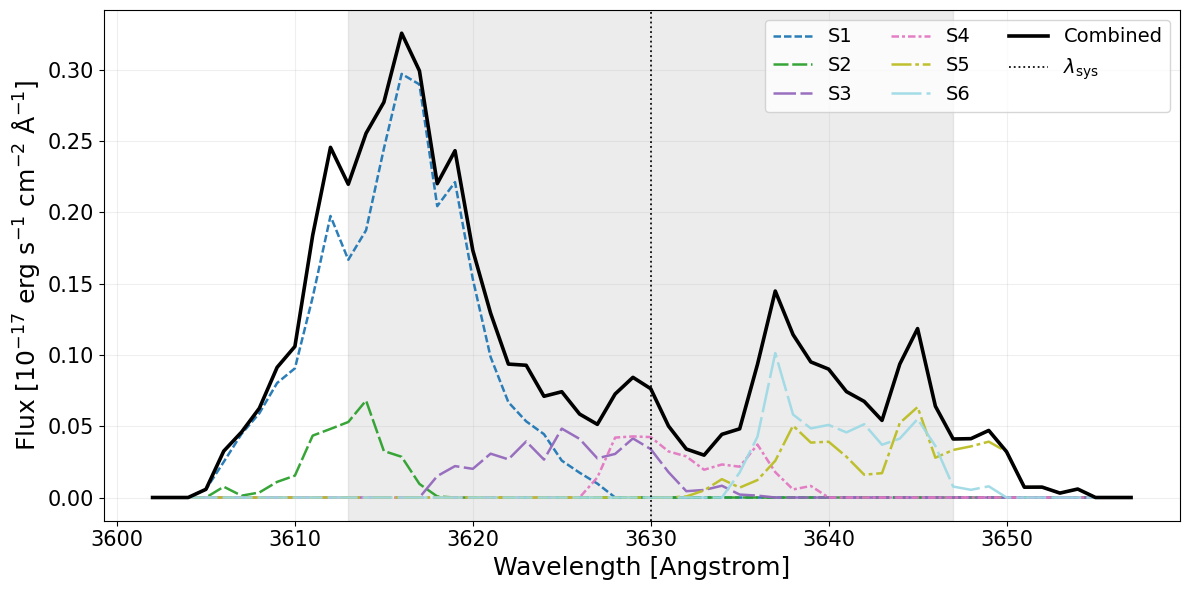

In [7]:
maskcube = fits.getdata(aks_folder / 'AKS.mask.fits')
structure_ids = [int(s) for s in np.unique(maskcube) if s > 0]
if not structure_ids:
    raise ValueError('No structures found in AKS.mask.fits')

# Match spectral depth between full cube and AKS mask
zmin, zmax = aks_params['zmin'], aks_params['zmax']
cube_match = cube[zmin:zmax + 1]

# Wavelength axis from header WCS
crval3 = float(header.get('CRVAL3', 0.0))
crpix3 = float(header.get('CRPIX3', 1.0))
dlam = abs(float(header.get('CDELT3', header.get('CD3_3', 1.0))))
wavelength = crval3 + ((np.arange(cube_match.shape[0]) + 1) - crpix3) * dlam

# Systemic Ly-alpha wavelength from dataset physics params
z_sys = redshift
dz_sys = redshift_err
lambda_sys = line_rest_aa * (1.0 + z_sys)
lambda_sys_err = line_rest_aa * dz_sys

# Restrict to spectral layers with detected structures +/- margin pixels
z_support = np.any(maskcube > 0, axis=(1, 2))
if not np.any(z_support):
    raise ValueError('No spectral support found in AKS mask')
idx = np.where(z_support)[0]
margin_pix = 3
z0 = max(int(idx.min()) - margin_pix, 0)
z1 = min(int(idx.max()) + margin_pix, cube_match.shape[0] - 1)
sl = slice(z0, z1 + 1)

# Distinct dash patterns for colorblind-friendly differentiation
dash_patterns = [
    (0, (3, 1.2)),
    (0, (6, 1.5)),
    (0, (9, 1.8)),
    (0, (3, 1.2, 1.2, 1.2)),
    (0, (8, 1.5, 1.5, 1.5)),
    (0, (12, 2.0)),
]
colors = plt.cm.tab20(np.linspace(0, 1, max(len(structure_ids), 2)))

fig, ax = plt.subplots(figsize=(12, 6))

# Spectra plot typography
FONT_AXIS = 18
FONT_TICK = 15
FONT_LEGEND = 14

combined_spec = np.zeros(cube_match.shape[0], dtype=float)
for i, sid in enumerate(structure_ids):
    mask = (maskcube == sid)
    spec = np.nansum(cube_match * mask, axis=(1, 2))
    combined_spec += spec
    ls = dash_patterns[i % len(dash_patterns)]
    ax.plot(
        wavelength[sl],
        spec[sl],
        color=colors[i],
        lw=1.8,
        linestyle=ls,
        alpha=0.95,
        label=f'S{i+1}',
    )

# Combined flux in black
ax.plot(wavelength[sl], combined_spec[sl], color='black', lw=2.6, linestyle='-', label='Combined')

# Systemic wavelength marker and uncertainty band
ax.axvline(lambda_sys, color='black', lw=1.3, linestyle=':', alpha=0.95, label=r'$\lambda_{\rm sys}$')
ax.axvspan(lambda_sys - lambda_sys_err, lambda_sys + lambda_sys_err, color='gray', alpha=0.15)

bunit = str(header.get('BUNIT', 'FLAM')).strip().upper()
if bunit == 'FLAM':
    flux_label = r'Flux [$10^{-17}$ $\mathrm{erg\ s^{-1}\ cm^{-2}\ \AA^{-1}}$]'
else:
    flux_label = f'Flux [$10^{{-17}}$ {bunit}]'

ax.set_xlabel('Wavelength [Angstrom]', fontsize=FONT_AXIS)
ax.set_ylabel(flux_label, fontsize=FONT_AXIS)
ax.tick_params(axis='both', labelsize=FONT_TICK)
ax.grid(alpha=0.2)
ax.legend(ncol=3, fontsize=FONT_LEGEND)
plt.tight_layout()

plots_folder.mkdir(parents=True, exist_ok=True)
spec_out = plots_folder / 'raw_spectra_by_structure.pdf'
fig.savefig(spec_out, dpi=300)
print(
    f'Saved: {spec_out.resolve()} | z_sys={z_sys:.3f}+-{dz_sys:.3f} '
    f'| lambda_sys={lambda_sys:.2f}+-{lambda_sys_err:.2f} Angstrom '
    f'| z-range={z0}:{z1} | lambda=[{wavelength[z0]:.2f}, {wavelength[z1]:.2f}]'
)
plt.show()


## 5) Load moment maps and plot
Loads saved moment maps and produces the final 2x2 panel(s).

Figures are generated per detected structure, with dynamic figure dimensions based
on structure shape and fixed pixel/text scale across outputs.


AKS benchmark structure: s1 (area=831 px)
  nvox  limits=(0.0, 17.0) ticks=[ 0.  5. 10. 15.]
  IM    limits=(-20.5, -18.5) ticks=[-20.5 -20.  -19.5 -19.  -18.5]
  cen   limits=(-1000.0, 1000.0) ticks=[-1000.  -500.     0.   500.  1000.]
  fwhm  limits=(0.0, 1000.0) ticks=[   0.  200.  400.  600.  800. 1000.]
AKS structure IDs to plot: [1, 2, 3, 4, 5, 6]
Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/aks_moments_1.pdf | fig_size=15.01x7.93 in | pixel=0.08 in


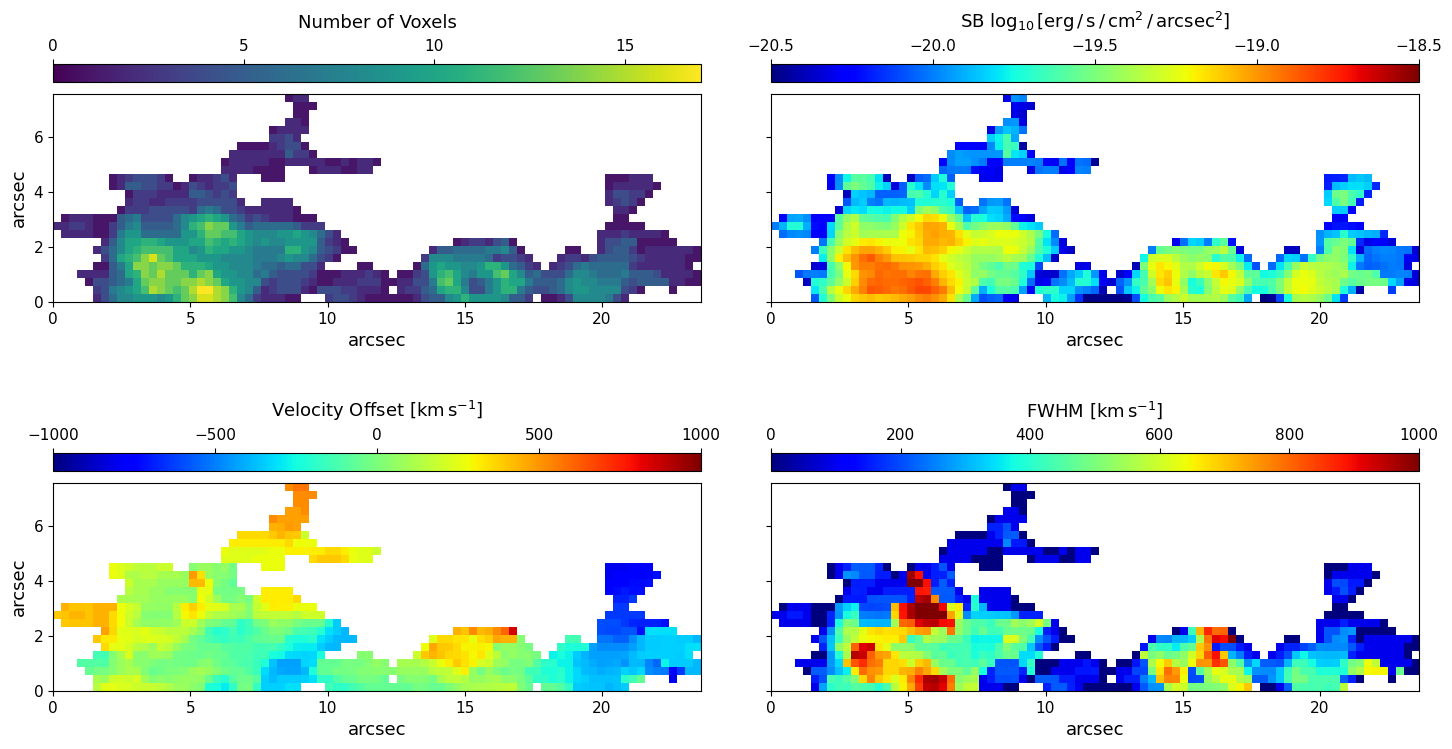

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/aks_moments_2.pdf | fig_size=7.33x6.65 in | pixel=0.08 in


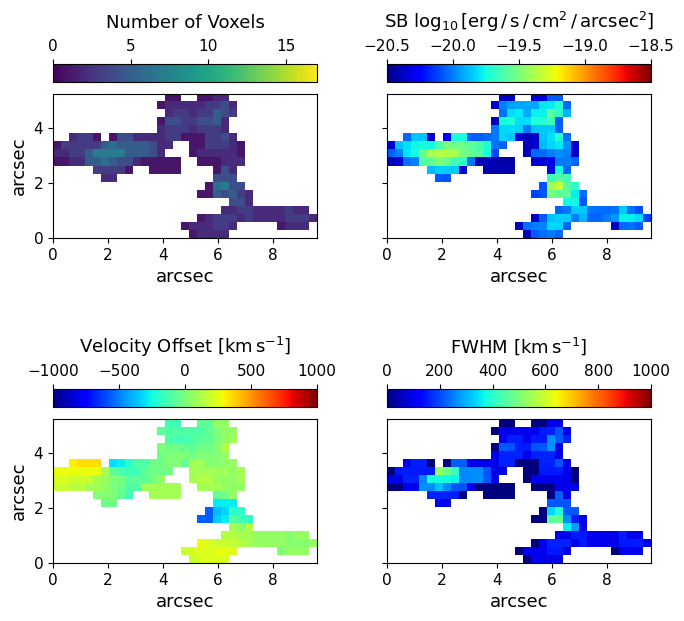

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/aks_moments_3.pdf | fig_size=7.81x6.97 in | pixel=0.08 in


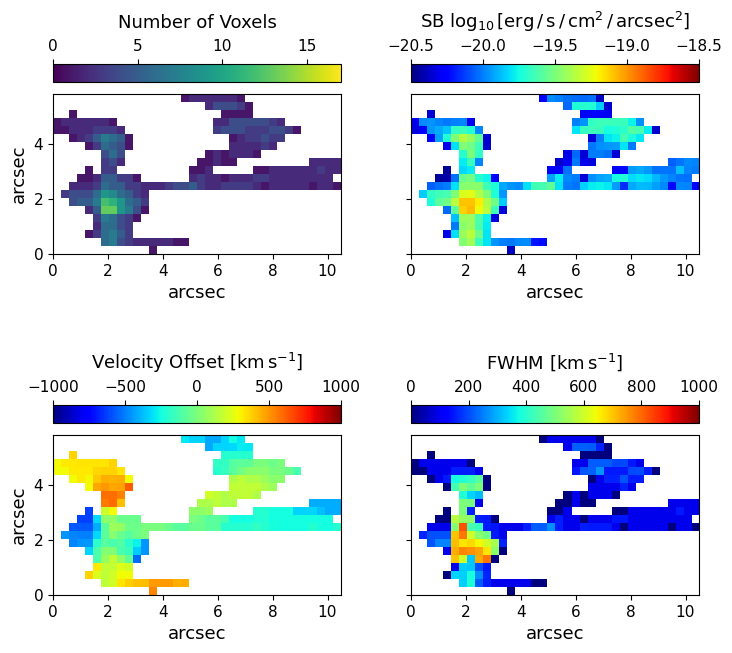

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/aks_moments_4.pdf | fig_size=6.05x6.01 in | pixel=0.08 in


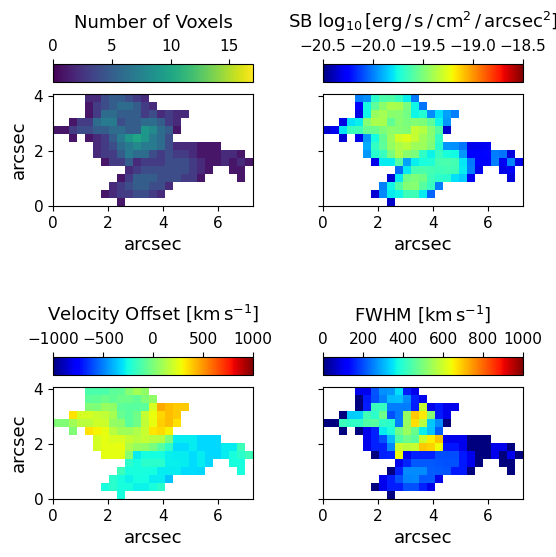

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/aks_moments_5.pdf | fig_size=6.69x8.41 in | pixel=0.08 in


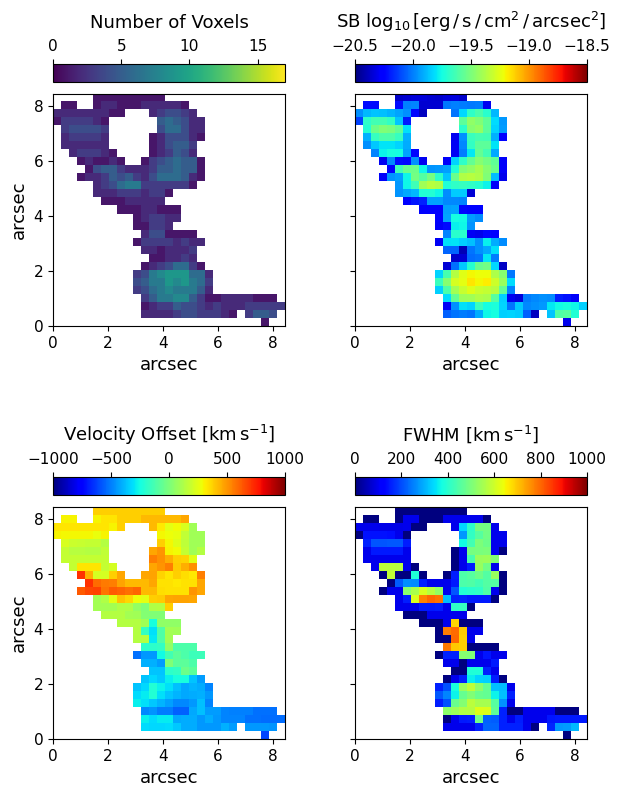

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/aks_moments_6.pdf | fig_size=6.21x7.13 in | pixel=0.08 in


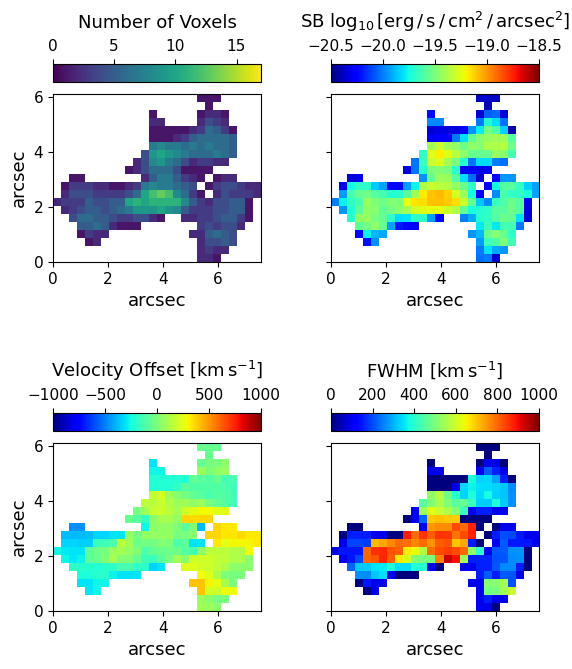

RAW benchmark structure: s1 (area=826 px)
  nvox  limits=(0.0, 17.0) ticks=[ 0.  5. 10. 15.]
  IM    limits=(-20.5, -18.5) ticks=[-20.5 -20.  -19.5 -19.  -18.5]
  cen   limits=(-1000.0, 1000.0) ticks=[-1000.  -500.     0.   500.  1000.]
  fwhm  limits=(0.0, 1000.0) ticks=[   0.  200.  400.  600.  800. 1000.]
RAW structure IDs to plot: [1, 2, 3, 4, 5, 6]
Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/raw_moments_1.pdf | fig_size=15.01x7.93 in | pixel=0.08 in


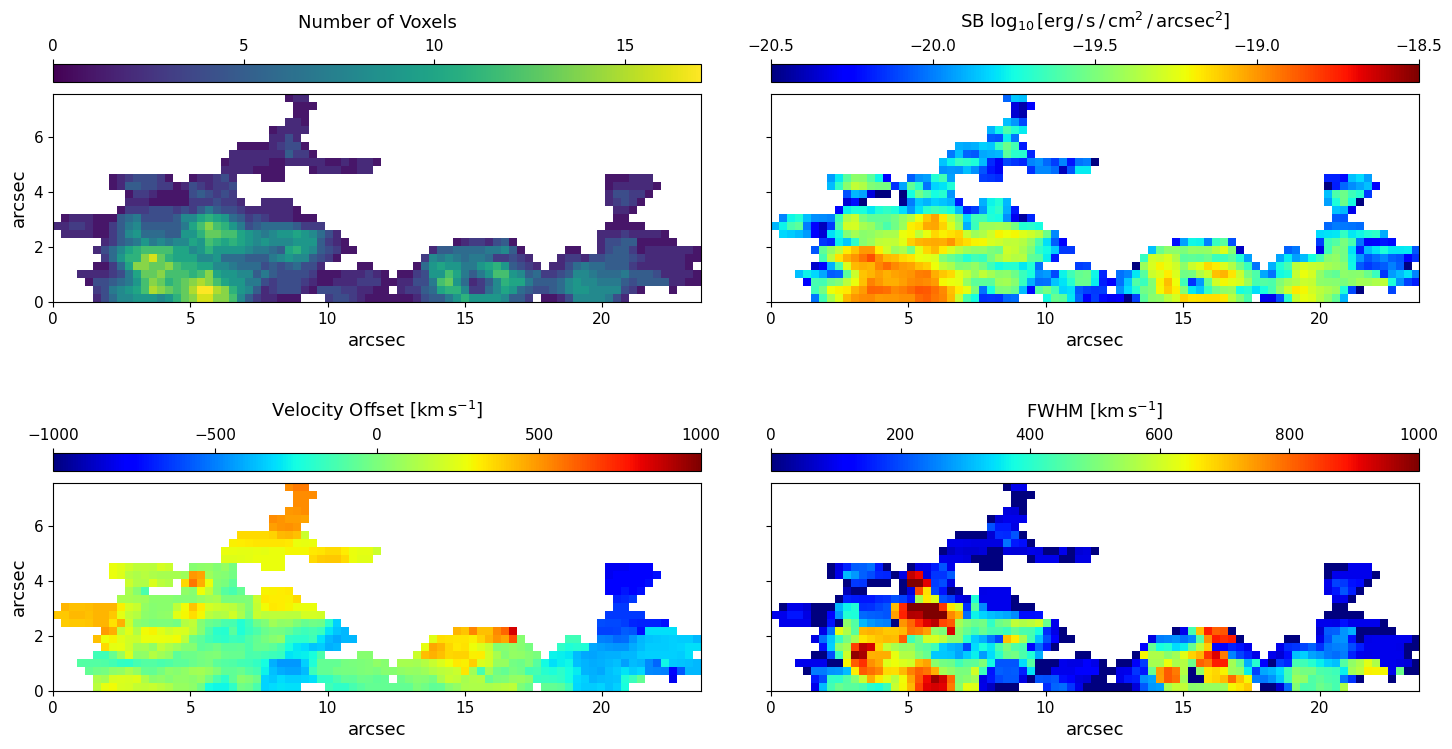

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/raw_moments_2.pdf | fig_size=7.33x6.65 in | pixel=0.08 in


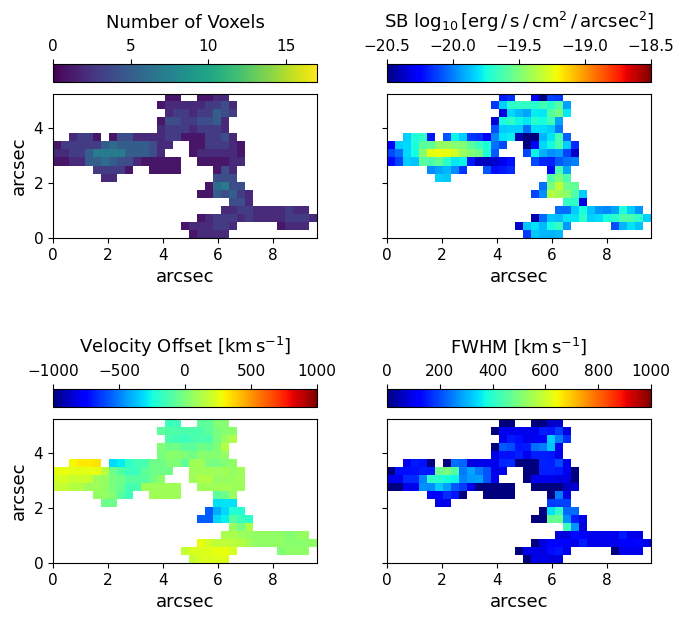

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/raw_moments_3.pdf | fig_size=7.81x6.97 in | pixel=0.08 in


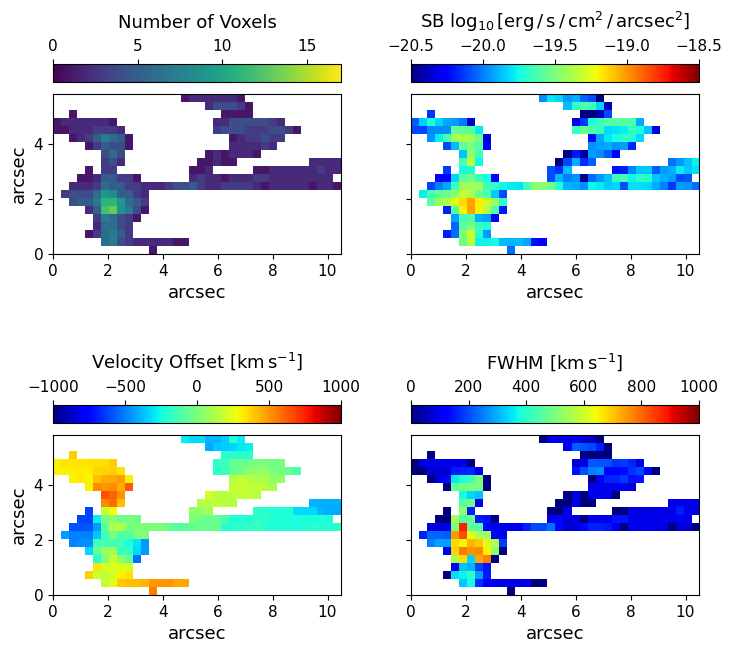

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/raw_moments_4.pdf | fig_size=6.05x6.01 in | pixel=0.08 in


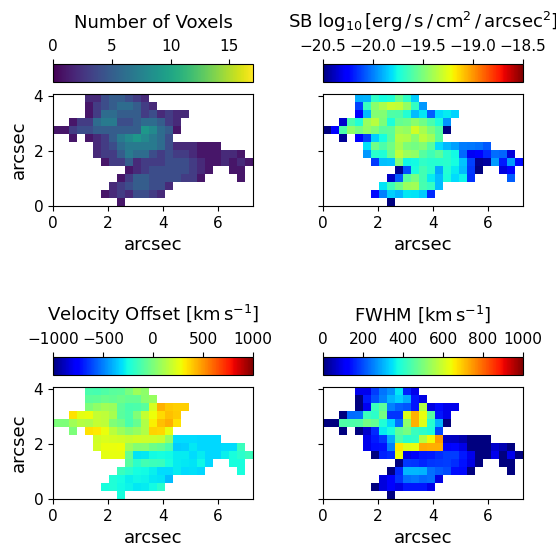

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/raw_moments_5.pdf | fig_size=6.69x8.41 in | pixel=0.08 in


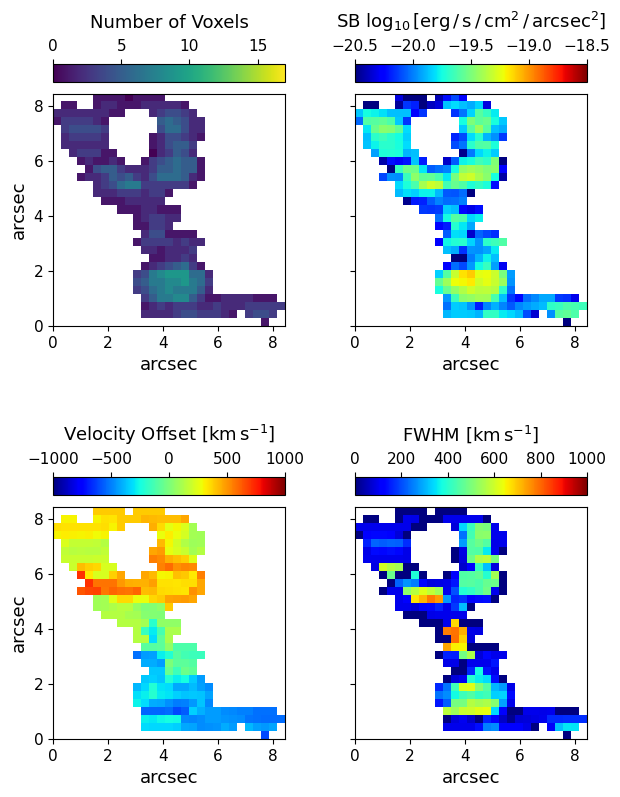

Saved: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/raw_moments_6.pdf | fig_size=6.21x7.13 in | pixel=0.08 in


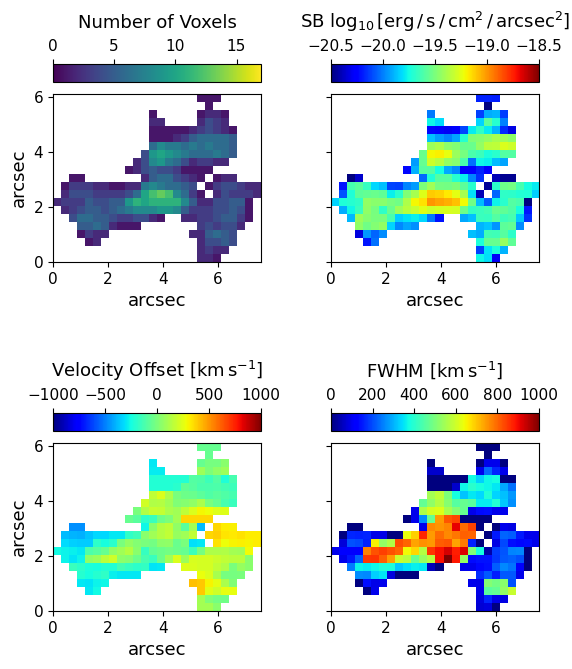

In [31]:
# Plot all structure IDs by default. To force specific IDs, set for example:
# plot_structure_ids = [1, 3]
plot_structure_ids = None

moments_subcube_dir = moments_folder / 'subcubes'

# Fixed rendering scale so each data pixel has the same physical size in every output.
PIXEL_SIZE_INCH = 0.08

# Typography and ticks (constant across all output figures)
FONT_LABEL = 13
FONT_TICK = 11
FONT_CBAR_LABEL = 13


def discover_structure_ids(prefix):
    ids = []
    for f in moments_subcube_dir.glob(f'{prefix}.*.IM.fits'):
        parts = f.name.split('.')
        if len(parts) >= 4 and parts[1].isdigit():
            ids.append(int(parts[1]))
    return sorted(set(ids))


def _nice_step(span, target_n=5):
    if not np.isfinite(span) or span <= 0:
        return 1.0
    raw = span / max(target_n - 1, 1)
    exp = 10 ** np.floor(np.log10(raw))
    for m in [1, 2, 2.5, 5, 10]:
        step = m * exp
        if step >= raw:
            return float(step)
    return float(10 * exp)


def _thin_ticks(ticks, max_ticks=7):
    ticks = np.asarray(ticks, dtype=float)
    if ticks.size <= max_ticks:
        return ticks
    step = int(np.ceil(ticks.size / max_ticks))
    return ticks[::step]


def _benchmark_from_largest_structure(prefix):
    ids = discover_structure_ids(prefix)
    if not ids:
        raise FileNotFoundError(f'No {prefix} moment files found in {moments_subcube_dir}')

    # Largest = structure with the maximum finite footprint in fwhm map.
    areas = {}
    for sid in ids:
        arr = fits.getdata(moments_subcube_dir / f'{prefix}.{sid}.fwhm.fits')
        areas[sid] = int(np.count_nonzero(np.isfinite(arr)))
    sid_ref = max(areas, key=areas.get)

    ref = {
        k: fits.getdata(moments_subcube_dir / f'{prefix}.{sid_ref}.{k}.fits')
        for k in ['nvox', 'IM', 'cen', 'fwhm']
    }

    bench = {}

    # nvox
    vals = ref['nvox'][np.isfinite(ref['nvox']) & (ref['nvox'] > 0)]
    vmax = np.percentile(vals, 99) if vals.size else 10
    vmax_true = np.nanmax(vals) if vals.size else vmax
    s = _nice_step(vmax, target_n=5)
    vmax_n = max(s, np.ceil(vmax / s) * s)
    ticks = _thin_ticks(np.arange(0, vmax_n + 0.5 * s, s), max_ticks=6)
    # Keep tick labels from robust scaling, but ensure colorbar limit includes true max.
    vmax_lim = max(float(vmax_n), float(vmax_true))
    bench['nvox'] = {'limits': (0.0, vmax_lim), 'ticks': ticks}

    # IM (already in log10)
    vals = ref['IM'][np.isfinite(ref['IM'])]
    if vals.size:
        lo, hi = np.percentile(vals, [2, 98])
    else:
        lo, hi = -20.0, -18.0
    s = _nice_step(hi - lo, target_n=6)
    lo_n = np.floor(lo / s) * s
    hi_n = np.ceil(hi / s) * s
    ticks = _thin_ticks(np.arange(lo_n, hi_n + 0.5 * s, s), max_ticks=7)
    bench['IM'] = {'limits': (float(lo_n), float(hi_n)), 'ticks': ticks}

    # cen (symmetric around zero)
    vals = ref['cen'][np.isfinite(ref['cen'])]
    vmax = np.percentile(np.abs(vals), 98) if vals.size else 200.0
    s = _nice_step(2 * vmax, target_n=7)
    vmax_n = max(s, np.ceil(vmax / s) * s)
    ticks = _thin_ticks(np.arange(-vmax_n, vmax_n + 0.5 * s, s), max_ticks=7)
    bench['cen'] = {'limits': (-float(vmax_n), float(vmax_n)), 'ticks': ticks}

    # fwhm
    vals = ref['fwhm'][np.isfinite(ref['fwhm']) & (ref['fwhm'] > 0)]
    hi = np.percentile(vals, 98) if vals.size else 500.0
    s = _nice_step(hi, target_n=6)
    hi_n = max(s, np.ceil(hi / s) * s)
    ticks = _thin_ticks(np.arange(0, hi_n + 0.5 * s, s), max_ticks=7)
    bench['fwhm'] = {'limits': (0.0, float(hi_n)), 'ticks': ticks}

    print(f'{prefix} benchmark structure: s{sid_ref} (area={areas[sid_ref]} px)')
    for k in ['nvox', 'IM', 'cen', 'fwhm']:
        lim = bench[k]['limits']
        t = bench[k]['ticks']
        print(f'  {k:5s} limits={lim} ticks={np.array2string(t, precision=2)}')

    return sid_ref, bench


def plot_moments(prefix, structure_id, out_name, bench):
    keys = ['nvox', 'IM', 'cen', 'fwhm']
    missing = []
    for k in keys:
        f = moments_subcube_dir / f'{prefix}.{structure_id}.{k}.fits'
        if not f.exists():
            missing.append(str(f))
    if missing:
        raise FileNotFoundError('Missing required moment FITS files\n' + '\n'.join(missing))

    data = {k: fits.getdata(moments_subcube_dir / f'{prefix}.{structure_id}.{k}.fits') for k in keys}

    valid = np.isfinite(data['fwhm'])
    if not np.any(valid):
        raise ValueError(f'FWHM map has no finite values for {prefix} structure {structure_id}.')

    y_idx, x_idx = np.where(valid)
    ymin, ymax = y_idx.min(), y_idx.max()
    xmin, xmax = x_idx.min(), x_idx.max()

    for k in keys:
        data[k] = data[k][ymin:ymax + 1, xmin:xmax + 1]

    yl, xl = data['cen'].shape
    extent = [0, xl * pix2asec, 0, yl * pix2asec]

    titles = [
        'Number of Voxels',
        r'SB $\rm{log_{10}\,[erg\,/\,s\,/\,cm^2\,/\,arcsec^2]}$',
        r'Velocity Offset $\rm{[km\,s^{-1}]}$',
        r'FWHM $\rm{[km\,s^{-1}]}$'
    ]
    cmaps = ['viridis', 'magma', 'RdBu_r', 'Reds']

    # Layout dimensions (inches). Panels scale with structure shape, while text stays fixed-size.
    panel_w = xl * PIXEL_SIZE_INCH
    panel_h = yl * PIXEL_SIZE_INCH

    # Margins and spacing in inches; tuned to prevent overlaps for colorbar titles/ticks + axis labels.
    left_m = 1.00
    right_m = 0.35
    bottom_m = 1.00
    top_m = 0.40
    col_gap = 0.70
    row_gap = 1.25

    cbar_gap = 0.12
    cbar_h = 0.18
    cbar_text_budget = 0.26

    band_h = panel_h + cbar_gap + cbar_h + cbar_text_budget
    fig_w = left_m + panel_w + col_gap + panel_w + right_m
    fig_h = bottom_m + band_h + row_gap + band_h + top_m

    fig = plt.figure(figsize=(fig_w, fig_h))

    # top-left, top-right, bottom-left, bottom-right
    panel_positions = [
        (left_m, bottom_m + band_h + row_gap),
        (left_m + panel_w + col_gap, bottom_m + band_h + row_gap),
        (left_m, bottom_m),
        (left_m + panel_w + col_gap, bottom_m),
    ]

    for j, (key, title, cmap, (x_in, y_in)) in enumerate(zip(keys, titles, cmaps, panel_positions)):
        ax = fig.add_axes([x_in / fig_w, y_in / fig_h, panel_w / fig_w, panel_h / fig_h])

        arr = data[key]
        lim = bench[key]['limits']
        im = ax.imshow(arr, origin='lower', cmap=cmap, vmin=lim[0], vmax=lim[1], extent=extent)

        ax.set_xlabel('arcsec', fontsize=FONT_LABEL)
        ax.tick_params(axis='both', labelsize=FONT_TICK)
        if j % 2 == 0:
            ax.set_ylabel('arcsec', fontsize=FONT_LABEL)
        else:
            ax.set_ylabel('')
            ax.set_yticklabels([])

        cax = fig.add_axes([
            x_in / fig_w,
            (y_in + panel_h + cbar_gap) / fig_h,
            panel_w / fig_w,
            cbar_h / fig_h,
        ])
        cbar = fig.colorbar(im, cax=cax, orientation='horizontal')
        cbar.ax.xaxis.set_ticks_position('top')
        cbar.ax.xaxis.set_label_position('top')
        cbar.ax.tick_params(labelsize=FONT_TICK)
        cbar.set_label(title, fontsize=FONT_CBAR_LABEL, labelpad=8)
        cbar.set_ticks(bench[key]['ticks'])

    plots_folder.mkdir(parents=True, exist_ok=True)
    output_path = plots_folder / out_name
    fig.savefig(output_path, dpi=300)
    print(f'Saved: {output_path.resolve()} | fig_size={fig_w:.2f}x{fig_h:.2f} in | pixel={PIXEL_SIZE_INCH} in')
    plt.show()


for prefix in ['AKS', 'RAW']:
    auto_ids = discover_structure_ids(prefix)
    if not auto_ids:
        raise FileNotFoundError(f'No {prefix} moment files found in {moments_subcube_dir}')

    if plot_structure_ids is None:
        ids_to_plot = auto_ids
    else:
        ids_to_plot = [int(x) for x in np.atleast_1d(plot_structure_ids)]

    _, bench = _benchmark_from_largest_structure(prefix)
    print(f'{prefix} structure IDs to plot: {ids_to_plot}')

    for sid in ids_to_plot:
        if sid not in auto_ids:
            print(f'Skipping {prefix} structure {sid}: not found')
            continue
        out_name = f"{prefix.lower()}_moments_{sid}.pdf"
        plot_moments(prefix, sid, out_name, bench)

# Backward-compatible default names when only one structure exists
aks_ids = discover_structure_ids('AKS')
raw_ids = discover_structure_ids('RAW')
if len(aks_ids) == 1:
    src = plots_folder / f'aks_moments_{aks_ids[0]}.pdf'
    dst = plots_folder / 'aks_moments.pdf'
    if src.exists():
        dst.write_bytes(src.read_bytes())
if len(raw_ids) == 1:
    src = plots_folder / f'raw_moments_{raw_ids[0]}.pdf'
    dst = plots_folder / 'raw_moments.pdf'
    if src.exists():
        dst.write_bytes(src.read_bytes())


nvox limits=(0.0, 15.0) ticks=[ 0.  5. 10. 15.]
IM limits=(-20.5, -18.5) ticks=[-20.5 -20.  -19.5 -19.  -18.5]
cen limits=(-2000.0, 2000.0) ticks=[-2000. -1000.     0.  1000.  2000.]
fwhm limits=(0.0, 1000.0) ticks=[   0.  200.  400.  600.  800. 1000.]
Saved combined field moments: /Users/nefiniq/Library/CloudStorage/GoogleDrive-cosmovis1216@gmail.com/My Drive/Github/astro-carla/KCWI/runs/RGguy_icubed_Lya/plots/r1-7_sum__w1-1.5_sum__snr3__z0-110__min500/aks_moments_combined_field.pdf
Systemic wavelength (Angstrom): 3629.99 | systemic pixel (cropped cube): 60.9906
Detected structures: [1, 2, 3, 4, 5, 6]


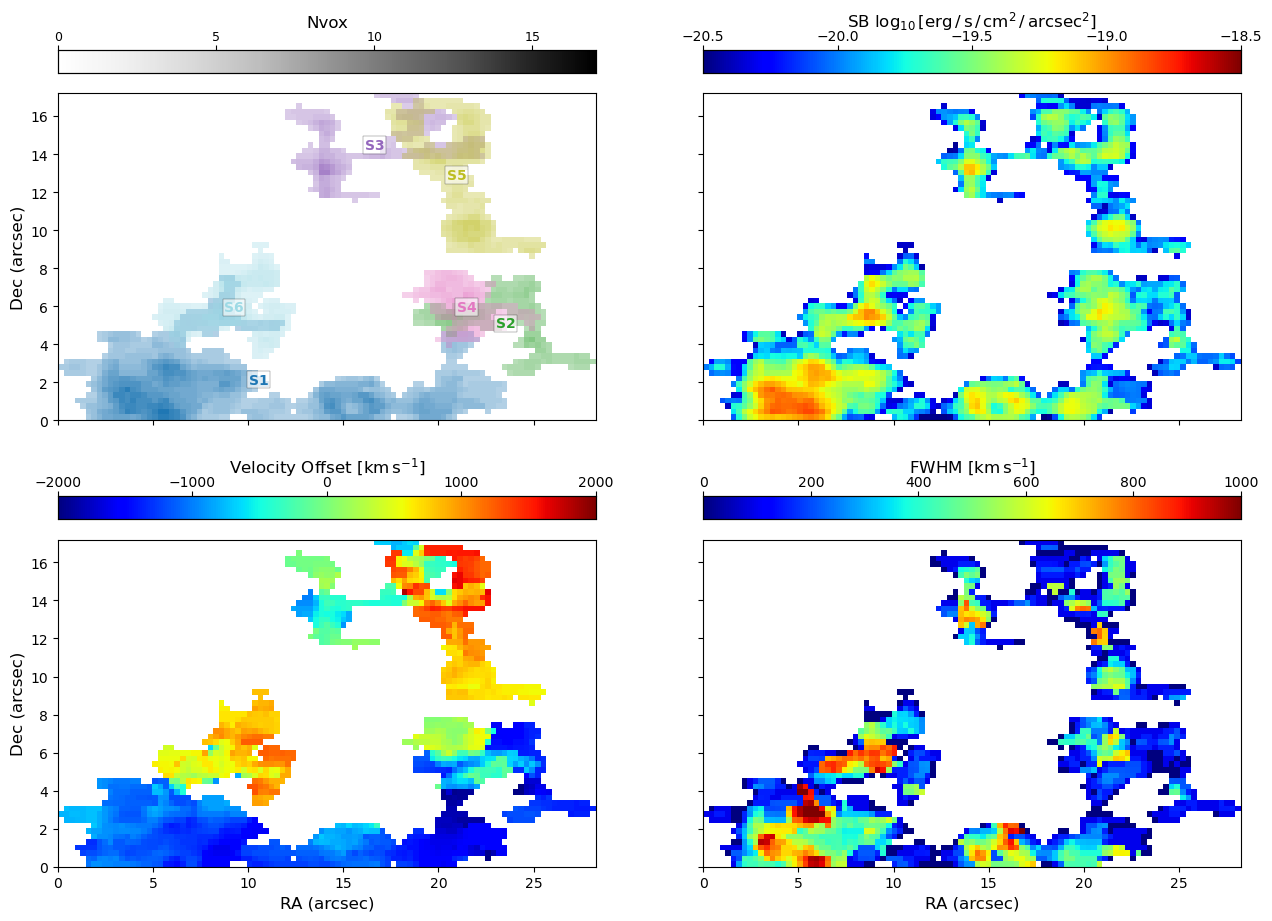

In [39]:
# 6) Combined moment maps (all structures in one field)
# This plots one 2x2 panel where all detected structures appear together
# in their full-field sky positions (RA/Dec offsets from FITS header).

combined_prefix = 'AKS'  # 'AKS' or 'RAW'
combined_out_name = f"{combined_prefix.lower()}_moments_combined_field.pdf"

# Use centralized shared parameters resolved in earlier cells.
kcwi2cgs_local = kcwi2cgs
disp2fwhm_local = disp2fwhm
pix2angstrom_local = pix2angstrom
redshift_local = redshift
line_rest_aa_local = line_rest_aa


def _pix2vel_local(x, pix2angstrom=pix2angstrom_local, z=redshift_local, line=line_rest_aa_local):
    return x * pix2angstrom * 3e5 / line / (1. + z)


def _nice_step(span, target_n=5):
    if not np.isfinite(span) or span <= 0:
        return 1.0
    raw = span / max(target_n - 1, 1)
    exp = 10 ** np.floor(np.log10(raw))
    for m in [1, 2, 2.5, 5, 10]:
        step = m * exp
        if step >= raw:
            return float(step)
    return float(10 * exp)


def _thin_ticks(ticks, max_ticks=7):
    ticks = np.asarray(ticks, dtype=float)
    if ticks.size <= max_ticks:
        return ticks
    step = int(np.ceil(ticks.size / max_ticks))
    return ticks[::step]



from matplotlib.colors import LinearSegmentedColormap

def _white_to_color_cmap(color_rgba, name='w2c'):
    r, g, b = color_rgba[:3]
    return LinearSegmentedColormap.from_list(name, [(1, 1, 1), (r, g, b)])

def _benchmark_fwhm_style_from_largest(prefix):
    moments_subcube_dir = moments_folder / 'subcubes'
    ids = []
    for f in moments_subcube_dir.glob(f'{prefix}.*.IM.fits'):
        parts = f.name.split('.')
        if len(parts) >= 4 and parts[1].isdigit():
            ids.append(int(parts[1]))
    ids = sorted(set(ids))
    if not ids:
        raise FileNotFoundError(f'No {prefix} moment files found in {moments_subcube_dir}')

    # Largest = structure with max finite fwhm footprint (same criterion as previous cell)
    areas = {}
    for sid in ids:
        arr = fits.getdata(moments_subcube_dir / f'{prefix}.{sid}.fwhm.fits')
        areas[sid] = int(np.count_nonzero(np.isfinite(arr)))
    sid_ref = max(areas, key=areas.get)

    ref_fwhm = fits.getdata(moments_subcube_dir / f'{prefix}.{sid_ref}.fwhm.fits')
    vals = ref_fwhm[np.isfinite(ref_fwhm) & (ref_fwhm > 0)]
    hi = np.percentile(vals, 98) if vals.size else 500.0
    step = _nice_step(hi, target_n=6)
    hi_n = max(step, np.ceil(hi / step) * step)
    ticks = _thin_ticks(np.arange(0, hi_n + 0.5 * step, step), max_ticks=7)
    return sid_ref, {'limits': (0.0, float(hi_n)), 'ticks': ticks}


def _benchmark_nvox_style_from_largest(prefix):
    moments_subcube_dir = moments_folder / 'subcubes'
    ids = []
    for f in moments_subcube_dir.glob(f'{prefix}.*.IM.fits'):
        parts = f.name.split('.')
        if len(parts) >= 4 and parts[1].isdigit():
            ids.append(int(parts[1]))
    ids = sorted(set(ids))
    if not ids:
        raise FileNotFoundError(f'No {prefix} moment files found in {moments_subcube_dir}')

    areas = {}
    for sid in ids:
        arr = fits.getdata(moments_subcube_dir / f'{prefix}.{sid}.fwhm.fits')
        areas[sid] = int(np.count_nonzero(np.isfinite(arr)))
    sid_ref = max(areas, key=areas.get)

    ref_nvox = fits.getdata(moments_subcube_dir / f'{prefix}.{sid_ref}.nvox.fits')
    vals = ref_nvox[np.isfinite(ref_nvox) & (ref_nvox > 0)]
    vmax = np.percentile(vals, 99) if vals.size else 10
    vmax_true = np.nanmax(vals) if vals.size else vmax
    step = _nice_step(vmax, target_n=5)
    vmax_n = max(step, np.ceil(vmax / step) * step)
    ticks = _thin_ticks(np.arange(0, vmax_n + 0.5 * step, step), max_ticks=6)
    vmax_lim = max(float(vmax_n), float(vmax_true))
    return sid_ref, {'limits': (0.0, vmax_lim), 'ticks': ticks}


def _combined_limits(maps):
    bench = {}

    vals = maps['nvox'][np.isfinite(maps['nvox']) & (maps['nvox'] > 0)]
    vmax = np.percentile(vals, 99.0) if vals.size else 10.0
    s = _nice_step(vmax, target_n=5)
    vmax_n = max(s, np.ceil(vmax / s) * s)
    bench['nvox'] = {'limits': (0.0, float(vmax_n)), 'ticks': _thin_ticks(np.arange(0, vmax_n + 0.5 * s, s), 6)}

    vals = maps['IM'][np.isfinite(maps['IM'])]
    lo, hi = (np.percentile(vals, [2.0, 98.0]) if vals.size else (-20.0, -18.0))
    s = _nice_step(hi - lo, target_n=6)
    lo_n = np.floor(lo / s) * s
    hi_n = np.ceil(hi / s) * s
    bench['IM'] = {'limits': (float(lo_n), float(hi_n)), 'ticks': _thin_ticks(np.arange(lo_n, hi_n + 0.5 * s, s), 7)}

    # Velocity offset: symmetric and robust to outliers.
    vals = maps['cen'][np.isfinite(maps['cen'])]
    vmax = np.percentile(np.abs(vals), 97.5) if vals.size else 200.0
    vmax = max(vmax, 20.0)
    s = _nice_step(2.0 * vmax, target_n=7)
    vmax_n = max(s, np.ceil(vmax / s) * s)
    bench['cen'] = {'limits': (-float(vmax_n), float(vmax_n)), 'ticks': _thin_ticks(np.arange(-vmax_n, vmax_n + 0.5 * s, s), 7)}

    # FWHM: robust high-end cap, anchored at zero.
    vals = maps['fwhm'][np.isfinite(maps['fwhm']) & (maps['fwhm'] > 0)]
    hi = np.percentile(vals, 97.5) if vals.size else 500.0
    hi = max(hi, 50.0)
    s = _nice_step(hi, target_n=6)
    hi_n = max(s, np.ceil(hi / s) * s)
    bench['fwhm'] = {'limits': (0.0, float(hi_n)), 'ticks': _thin_ticks(np.arange(0, hi_n + 0.5 * s, s), 7)}

    return bench


maskcube = fits.getdata(aks_folder / 'AKS.mask.fits')
structure_ids = sorted([int(s) for s in np.unique(maskcube) if s > 0])
if not structure_ids:
    raise ValueError('No structures detected in AKS.mask.fits')

sid_nvox_ref, nvox_style = _benchmark_nvox_style_from_largest(combined_prefix)
sid_fwhm_ref, fwhm_style = _benchmark_fwhm_style_from_largest(combined_prefix)

zmin, zmax = aks_params['zmin'], aks_params['zmax']
if combined_prefix == 'AKS':
    cube_work = fits.getdata(aks_folder / 'AKS.fits').astype(np.float32)
elif combined_prefix == 'RAW':
    cube_work = cube[zmin:zmax + 1].astype(np.float32)
else:
    raise ValueError("combined_prefix must be 'AKS' or 'RAW'")

if cube_work.shape != maskcube.shape:
    raise ValueError(f'Shape mismatch: cube={cube_work.shape}, mask={maskcube.shape}')

valid3d = (maskcube > 0) & np.isfinite(cube_work)
flux = np.where(valid3d, cube_work, 0.0)

z_axis = np.arange(cube_work.shape[0], dtype=np.float32)[:, None, None]
m0 = np.sum(flux, axis=0)
m0_safe = np.where(m0 > 0, m0, np.nan)

# 1st and 2nd moments in spectral-pixel units.
m1 = np.sum(flux * z_axis, axis=0) / m0_safe
var2 = np.sum(flux * (z_axis - m1[None, :, :]) ** 2, axis=0) / m0_safe
sigma = np.sqrt(np.clip(var2, 0.0, np.inf))
fwhm_pix = disp2fwhm_local * sigma

# Systemic centroid from dataset redshift (not flux-weighted global centroid).
crval3 = float(header.get('CRVAL3', 0.0))
crpix3 = float(header.get('CRPIX3', 1.0))
dlam = abs(float(header.get('CDELT3', header.get('CD3_3', 1.0))))
lambda_sys = line_rest_aa_local * (1.0 + redshift_local)

# Convert systemic wavelength to cube index in the cropped cube frame.
sys_pix_full = ((lambda_sys - crval3) / dlam) + crpix3 - 1.0
sys_pix = sys_pix_full - float(zmin)
cen_pix = m1 - sys_pix

nvox = np.sum(valid3d, axis=0).astype(np.float32)

im_log = np.full_like(m0, np.nan, dtype=np.float32)
sb = m0 * kcwi2cgs_local
pos = sb > 0
im_log[pos] = np.log10(sb[pos])

cen_vel = _pix2vel_local(cen_pix).astype(np.float32)
fwhm_vel = _pix2vel_local(fwhm_pix).astype(np.float32)

valid2d = np.any(valid3d, axis=0)
im_log[~valid2d] = np.nan
cen_vel[~valid2d] = np.nan
fwhm_vel[~valid2d] = np.nan
nvox[~valid2d] = np.nan

# Crop to detected footprint while keeping global spatial arrangement.
y_idx, x_idx = np.where(valid2d)
if len(y_idx) == 0:
    raise ValueError('No valid 2D footprint found after masking')
ymin, ymax = y_idx.min(), y_idx.max()
xmin, xmax = x_idx.min(), x_idx.max()

im_log = im_log[ymin:ymax+1, xmin:xmax+1]
cen_vel = cen_vel[ymin:ymax+1, xmin:xmax+1]
fwhm_vel = fwhm_vel[ymin:ymax+1, xmin:xmax+1]
nvox = nvox[ymin:ymax+1, xmin:xmax+1]

# Force FWHM map values to match per-structure maps from previous cell.
moments_subcube_dir = moments_folder / 'subcubes'
fwhm_from_sub = np.full_like(fwhm_vel, np.nan, dtype=np.float32)
for sid in structure_ids:
    fpath = moments_subcube_dir / f'{combined_prefix}.{sid}.fwhm.fits'
    if not fpath.exists():
        continue

    struct_mask3d = (maskcube == sid)
    mask2d_sid = np.any(struct_mask3d, axis=0)
    y_idx_sid, x_idx_sid = np.where(mask2d_sid)
    if len(y_idx_sid) == 0:
        continue
    ys0, ys1 = y_idx_sid.min(), y_idx_sid.max()
    xs0, xs1 = x_idx_sid.min(), x_idx_sid.max()

    # Local bbox indices in global-crop coordinates
    y0c, y1c = ys0 - ymin, ys1 - ymin
    x0c, x1c = xs0 - xmin, xs1 - xmin

    fsub = fits.getdata(fpath).astype(np.float32)
    # Robust shape handling (trim to overlap if needed)
    h = min(fsub.shape[0], y1c - y0c + 1)
    w = min(fsub.shape[1], x1c - x0c + 1)
    if h <= 0 or w <= 0:
        continue

    target = fwhm_from_sub[y0c:y0c+h, x0c:x0c+w]
    mask2d_crop = mask2d_sid[ymin:ymax+1, xmin:xmax+1]
    mask_local = mask2d_crop[y0c:y0c+h, x0c:x0c+w]
    vals = fsub[:h, :w]
    target[mask_local] = vals[mask_local]
    fwhm_from_sub[y0c:y0c+h, x0c:x0c+w] = target

# Use stitched per-structure FWHM where available.
fwhm_vel = np.where(np.isfinite(fwhm_from_sub), fwhm_from_sub, fwhm_vel)

# Use RA/Dec axes starting at 0 arcsec (same style as previous cell).
yl, xl = im_log.shape
extent = [0, xl * pix2asec, 0, yl * pix2asec]

maps = {'nvox': nvox, 'IM': im_log, 'cen': cen_vel, 'fwhm': fwhm_vel}
keys = ['nvox', 'IM', 'cen', 'fwhm']
titles = [
    'Number of Voxels',
    r'SB $\rm{log_{10}\,[erg\,/\,s\,/\,cm^2\,/\,arcsec^2]}$',
    r'Velocity Offset $\rm{[km\,s^{-1}]}$',
    r'FWHM $\rm{[km\,s^{-1}]}$'
]
cmaps = ['viridis', 'magma', 'RdBu_r', 'Reds']

# Region styles (match spectra plot)
dash_patterns = [
    (0, (3, 1.2)),
    (0, (6, 1.5)),
    (0, (9, 1.8)),
    (0, (3, 1.2, 1.2, 1.2)),
    (0, (8, 1.5, 1.5, 1.5)),
    (0, (12, 2.0)),
]
region_colors = plt.cm.tab20(np.linspace(0, 1, max(len(structure_ids), 2)))

bench = _combined_limits(maps)
# Force FWHM scale/ticks to match previous-cell benchmark style.
bench['fwhm'] = fwhm_style
for k in keys:
    print(f"{k} limits={bench[k]['limits']} ticks={np.array2string(bench[k]['ticks'], precision=2)}")

# 2D region masks for per-structure contours/labels on SB map
region2d_masks = {
    sid: np.any(maskcube == sid, axis=0)[ymin:ymax + 1, xmin:xmax + 1]
    for sid in structure_ids
}

# Fixed nvox scale from the largest structure (by projected area).
region_areas = {sid: int(np.count_nonzero(region2d_masks[sid])) for sid in structure_ids}
sid_largest = max(region_areas, key=region_areas.get)
nvox_largest = np.sum((maskcube == sid_largest), axis=0)[ymin:ymax + 1, xmin:xmax + 1].astype(float)
nvox_ref_max = np.nanmax(nvox_largest[np.isfinite(nvox_largest)])
if not np.isfinite(nvox_ref_max) or nvox_ref_max <= 0:
    nvox_ref_max = 1.0

# Layout: keep colorbars visually tied to their own panels.
fig, ax_grid = plt.subplots(2, 2, figsize=(13.0, 9.2))
fig.subplots_adjust(top=0.95, bottom=0.08, left=0.07, right=0.98, hspace=0.26, wspace=0.20)
axes_img = [ax_grid[0, 0], ax_grid[0, 1], ax_grid[1, 0], ax_grid[1, 1]]

# Dedicated top colorbar axes per panel
axes_cbar = []
for ax in axes_img:
    pos = ax.get_position()
    cbar_gap = 0.008
    cbar_h = 0.025
    cax = fig.add_axes([pos.x0, pos.y1 + cbar_gap, pos.width, cbar_h])
    axes_cbar.append(cax)

for j, (ax, cax, key, title, cmap) in enumerate(zip(axes_img, axes_cbar, keys, titles, cmaps)):
    if key == 'nvox':
        # Layered per-structure nvox map: white->region color with transparency.
        ax.set_facecolor('white')
        nx = maps['nvox'].shape[1]
        ny = maps['nvox'].shape[0]
        ex0, ex1, ey0, ey1 = extent[0], extent[1], extent[2], extent[3]
        dx = (ex1 - ex0) / nx
        dy = (ey1 - ey0) / ny

        # Draw each structure with its own colormap and alpha to reveal overlaps.
        for i, sid in enumerate(structure_ids):
            m = region2d_masks[sid]
            if not np.any(m):
                continue

            nvox_i = np.sum((maskcube == sid), axis=0)[ymin:ymax + 1, xmin:xmax + 1].astype(float)
            nvox_i[~m] = np.nan
            vmax_i = np.nanmax(nvox_i)
            if not np.isfinite(vmax_i) or vmax_i <= 0:
                continue

            region_color = region_colors[i % len(region_colors)]

            # Alpha-only encoding on fixed largest-structure nvox scale:
            # 70% transparency -> 0% transparency.
            alpha_i = np.where(np.isfinite(nvox_i), 0.30 + 0.70 * (nvox_i / nvox_ref_max), 0.0)
            alpha_i = np.clip(alpha_i, 0.0, 1.0)

            # Render with a constant structure color; nvox is represented by alpha.
            rgba = np.zeros((nvox_i.shape[0], nvox_i.shape[1], 4), dtype=float)
            rgba[..., 0] = region_color[0]
            rgba[..., 1] = region_color[1]
            rgba[..., 2] = region_color[2]
            rgba[..., 3] = alpha_i
            rgba[~np.isfinite(nvox_i), 3] = 0.0
            ax.imshow(
                rgba,
                origin='lower',
                extent=extent,
                interpolation='nearest',
            )

            # Region labels S1, S2, ...
            yy, xx = np.where(m)
            xc = ex0 + (xx.mean() + 0.5) * dx
            yc = ey0 + (yy.mean() + 0.5) * dy
            ax.text(
                xc,
                yc,
                f'S{i+1}',
                color=region_color,
                fontsize=10,
                fontweight='bold',
                ha='center',
                va='center',
                bbox=dict(facecolor='white', edgecolor='black', linewidth=0.3, alpha=0.6, pad=1.2),
            )

        # Single grayscale colorbar for all structures (represents relative nvox->alpha mapping).
        cax.clear()
        from matplotlib.colors import Normalize
        from matplotlib.cm import ScalarMappable
        sm = ScalarMappable(norm=Normalize(vmin=0.0, vmax=float(nvox_style['limits'][1])), cmap='Greys')
        sm.set_array([])
        cbar_n = fig.colorbar(sm, cax=cax, orientation='horizontal')
        cbar_n.ax.xaxis.set_ticks_position('top')
        cbar_n.ax.xaxis.set_label_position('top')
        cbar_n.set_ticks(nvox_style['ticks'])
        cbar_n.set_label(f'Nvox', fontsize=12, labelpad=2)
        cbar_n.ax.tick_params(labelsize=9, pad=1)
        frame_lw_n = ax.spines['left'].get_linewidth()
        cbar_n.outline.set_edgecolor('black')
        cbar_n.outline.set_linewidth(frame_lw_n)
        for spine in cax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor('black')
            spine.set_linewidth(frame_lw_n)

    else:
        lim = bench[key]['limits']
        im = ax.imshow(maps[key], origin='lower', cmap=cmap, vmin=lim[0], vmax=lim[1], extent=extent)

        cbar = fig.colorbar(im, cax=cax, orientation='horizontal')
        cbar.ax.xaxis.set_ticks_position('top')
        cbar.ax.xaxis.set_label_position('top')
        cbar.set_ticks(bench[key]['ticks'])
        cbar.set_label(title, fontsize=12, labelpad=2)
        cbar.ax.tick_params(labelsize=10, pad=1)

        # Match colorbar border thickness to panel border thickness.
        frame_lw = ax.spines['left'].get_linewidth()
        cbar.outline.set_edgecolor('black')
        cbar.outline.set_linewidth(frame_lw)
        for spine in cax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor('black')
            spine.set_linewidth(frame_lw)

    if j < 2:
        ax.set_xlabel('')
        ax.set_xticklabels([])
    else:
        ax.set_xlabel('RA (arcsec)', fontsize=12)
    if j % 2 == 0:
        ax.set_ylabel('Dec (arcsec)', fontsize=12)
    else:
        ax.set_ylabel('')
        ax.set_yticklabels([])
    ax.tick_params(labelsize=10)

plots_folder.mkdir(parents=True, exist_ok=True)
out_path = plots_folder / combined_out_name
fig.savefig(out_path, dpi=300)
print(f'Saved combined field moments: {out_path.resolve()}')
print(f'Systemic wavelength (Angstrom): {lambda_sys:.2f} | systemic pixel (cropped cube): {sys_pix:.4f}')
print(f'Detected structures: {structure_ids}')
plt.show()
